In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

## Let's get the smaller CSV

In [2]:
import csv
filename = r"dataFolder/train.csv"
df = pd.read_csv(filename,encoding='latin-1')

In [4]:
df

,textID,text,selected_text,sentiment,Time of Tweet,Age of User,Country,Population -2020,Land Area (Km²),Density (P/Km²)
0,cb774db0d1,"I`d have responded, if I were going","I`d have responded, if I were going",neutral,morning,0-20,Afghanistan,38928346,652860.0,60
1,549e992a42,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD,negative,noon,21-30,Albania,2877797,27400.0,105
2,088c60f138,my boss is bullying me...,bullying me,negative,night,31-45,Algeria,43851044,2381740.0,18
3,9642c003ef,what interview! leave me alone,leave me alone,negative,morning,46-60,Andorra,77265,470.0,164
4,358bd9e861,"Sons of ****, why couldn`t they put them on t...","Sons of ****,",negative,noon,60-70,Angola,32866272,1246700.0,26
...,...,...,...,...,...,...,...,...,...,...
27476,4eac33d1c0,wish we could come see u on Denver husband l...,d lost,negative,night,31-45,Ghana,31072940,227540.0,137
27477,4f4c4fc327,I`ve wondered about rake to. The client has ...,", don`t force",negative,morning,46-60,Greece,10423054,128900.0,81
27478,f67aae2310,Yay good for both of you. Enjoy the break - y...,Yay good for both of you.,positive,noon,60-70,Grenada,112523,340.0,331
27479,ed167662a5,But it was worth it ****.,But it was worth it ****.,positive,night,70-100,Guatemala,17915568,107160.0,167


## How much data do we have?

In [5]:
df.shape

(27481, 10)

## Let's get only 5% of the data

In [6]:
import math

oneFifth = math.ceil(len(df) * 0.05)

## Let's only get a small sample of English tweets (for now)

In [7]:
df = df["text"].sample(oneFifth)

In [8]:
df.reset_index(drop=True, inplace=True)

## Let's check again

In [9]:
df.shape

(1375,)

## We declare helper functions, starting with removing URLS from our tweets

In [10]:
import re


def remove_urls(x):
    cleaned_string = re.sub(r'(https|http)?:\/\/(\w|\.|\/|\?|\=|\&|\%)*\b', '', str(x), flags=re.MULTILINE)
    return cleaned_string

## We remove emoticons

In [11]:
def deEmojify(x):
    regrex_pattern = re.compile(pattern = "["
        u"\U0001F600-\U0001F64F"  # emoticons
        u"\U0001F300-\U0001F5FF"  # symbols & pictographs
        u"\U0001F680-\U0001F6FF"  # transport & map symbols
        u"\U0001F1E0-\U0001F1FF"  # flags (iOS)
                           "]+", flags = re.UNICODE)
    return regrex_pattern.sub(r'', x)

## We replace consecutive whitespaces as one

In [12]:
def unify_whitespaces(x):
    cleaned_string = re.sub(r'\s+', ' ', x)
    return cleaned_string 

## We remove unwanted symbols but preserve sentence structure by maintaining "?" , ",", "!", and "."

In [13]:
def remove_symbols(x):
    cleaned_string = re.sub(r"[^a-zA-Z0-9?!.,]+", ' ', x)
    return cleaned_string  

## Let's preprocess the text data and utilize the helper functions that we declared

In [14]:
df

0       new neighbors are moving in.... off to give my...
1       Please Review Sunehre Ad Placement  http://tin...
2       Oh, had like the most amazing weekend, sunshin...
3        argh, sorry, he`s just been a thorn in my sid...
4            congrats, dreps! and good luck sa interview!
                              ...                        
1370     i`m pretty sure he`s every main character we`...
1371              pancakes!! with lemon and sugar thanks!
1372     Celebrity sighting: Spongebobs here! #BEA09  ...
1373     I left mine in music...i think i don`t have a...
1374             Mmm wasabi coated peanuts! Burns so good
Name: text, Length: 1375, dtype: str

In [15]:
df['text'] = df.str.lower()
df['text'] = df['text'].apply(remove_urls)
df['text'] = df['text'].apply(deEmojify)
df['text'] = df['text'].apply(remove_symbols)
df['text'] = df['text'].apply(unify_whitespaces)

## Let's check how our data looks like

In [19]:
df['text'].head()

0    new neighbors are moving in.... off to give my...
1                  please review sunehre ad placement 
2    oh, had like the most amazing weekend, sunshin...
3     argh, sorry, he s just been a thorn in my sid...
4         congrats, dreps! and good luck sa interview!
Name: text, dtype: str

## Let's install flair then suppress the status messages

In [ ]:
from flair.models import TextClassifier
from flair.data import Sentence
sia = TextClassifier.load('en-sentiment') #just like spacy we load english model

## Let's create a helper function using flair library and use the sentiment predict function

## Let's create the placeholder fields

In [17]:
df['Sentiment'] = ""
df['Sentiment_Score'] = np.nan

## Let's determine the sentiments

In [19]:
import swifter
df["Sentiment"],df["Sentiment_Score"] =  zip(*df["text"].swifter.apply(flair_prediction))

Pandas Apply:   0%|          | 0/17851 [00:00<?, ?it/s]

## Flair Sentiment Is Very Slow But Promises Better Performance than Rule-based Sentiment Analysis Libraries, if you sentiment analysis extraction is time-critical, dont use this

## Let's take a peek at the top 5 records/ rows

In [20]:
df.head().

,0,1,2,3,4
userid,1399390569437093889,303153745,1478332197627179010,1473020141244129280,1102942751509938176
username,Prakash97123023,IzzyVerena,WorstLegend,DGwantes,alene61x
acctdesc,NaN,Artist and Photographer,JOINT NFT COLLECTION\n| Marijuana | Weed | Can...,crypto lover #ETH #BTC #METAVERSE $ILV #NobleK...,SDÜ | GİT
location,NaN,"Manchester, UK",Opensea,sampalucan,"Uşak, Türkiye"
following,128,764,4996,533,390
followers,55,81,867,292,184
totaltweets,1057,7787,7027,104,2055
usercreatedts,2021-05-31 15:41:33.000000,2011-05-22 11:37:01.000000,2022-01-04 11:47:30.000000,2021-12-20 19:59:17.000000,2019-03-05 14:43:38.000000
tweetid,1497828671595298820,1498065331897647105,1497808286250573827,1497805229567672321,1497868991578132482
tweetcreatedts,2022-02-27 06:59:18,2022-02-27 22:39:42,2022-02-27 05:38:18,2022-02-27 05:26:09,2022-02-27 09:39:31


## Quick count of NEGATIVE vs POSITIVE sentiment tweets

In [21]:
df.groupby(["Sentiment"]).agg({'Sentiment_Score': ['count','mean']})

Sentiment_Score          
                    count      mean
Sentiment                          
NEGATIVE            12218  0.945157
POSITIVE             5633  0.887604

## Quick simple pie chart

<AxesSubplot:ylabel='tweetid'>

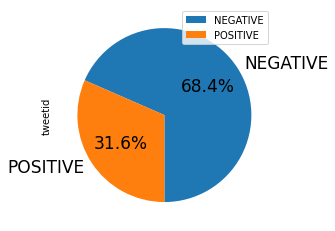

In [22]:
import matplotlib.pyplot as plt

df.groupby(['Sentiment']).sum().plot(kind='pie', y="tweetid", autopct='%1.1f%%', startangle=270, fontsize=17)
